# Lab 3 — Descriptive Statistics Assignment: Gym Membership Dataset

**School of Computer Science and Engineering (SOCSE) — RV University**

**Name:** _____Pradyumna Rao G Hosrkar **Roll No.:** __1RUA25CSE0325_____________  **Section:** _G______

---

## Instructions

- This is a follow-up to Lab 3 (descriptive statistics on the student survey dataset). The same
  concepts — central tendency, dispersion, distribution shape, and visualization — are applied here
  to a **new dataset** describing gym members, so you can practice choosing the right
  statistic rather than remembering the answer from Lab 3.
-
- Every question below has an empty code cell (marked `# TODO`) for your solution, and most also   have a markdown cell marked **Your answer:** for a short written interpretation. Write your
  interpretation in your own words — a correct number with no explanation will not receive full  marks for questions that ask you to interpret.
- Run your notebook **top to bottom** (Kernel → Restart & Run All) before submitting, and make sure
  it completes with no errors.
-

### Learning objectives
By the end of this assignment you should be able to: compute and correctly choose between mean,
median, and mode; compute and interpret variance, standard deviation, and IQR; use skewness and
kurtosis to identify non-normal distributions; and build/interpret histograms, box plots, and scatter plots to support (or challenge) what the summary statistics suggest.

In [1]:
# --- Core libraries used throughout the notebook (provided — no changes needed) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

print("Libraries loaded. Random seed set to", RANDOM_SEED)

Libraries loaded. Random seed set to 7


## Part 1 — The Dataset (provided, do not modify)

This dataset simulates **150 gym members**, with the same design idea as Lab 3: each numeric
feature is deliberately shaped differently, so no single statistic works well for all of them.

| Feature | Real-world meaning | Intended shape |
|---|---|---|
| `workout_duration_minutes` | Average length of a workout session | *(shape not disclosed — see Q7/Q8)* |
| `monthly_membership_fee_inr` | Monthly membership fee paid (₹) | *(shape not disclosed — see Q7/Q8)* |
| `attendance_percentage` | % of scheduled sessions actually attended | *(shape not disclosed — see Q7/Q8)* |
| `weekly_visit_count` | Number of gym visits per week | *(shape not disclosed — see Q7/Q8)* |
| `preferred_workout` | Favorite workout category | categorical |

Unlike Lab 3, the shapes are **not labeled** for you this time — figuring out which feature is
approximately normal, right-skewed, left-skewed, or bimodal (and *proving it* with statistics and
plots) is part of the assignment.

In [2]:
df=pd.read_csv("gym_members_synthetic.csv")
FEATURES = [ "workout_duration_minutes","monthly_membership_fee_inr","attendance_percentage","weekly_visit_count"]
df.head(8)

,member_id,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count,preferred_workout
0,M001,69.7,1690.0,71.7,1.3,Cardio
1,M002,81.0,2450.0,86.2,2.2,Weights
2,M003,62.6,2190.0,89.0,5.1,CrossFit
3,M004,65.7,3170.0,79.6,5.4,Cardio
4,M005,49.3,1050.0,80.7,1.5,Weights
5,M006,39.1,1180.0,88.0,5.0,Weights
6,M007,52.3,800.0,81.3,2.1,Weights
7,M008,73.0,2630.0,82.3,5.5,Yoga


### Q1 (2 marks) — Initial exploration

In the code cell below: display the shape of `df`, the data type of each column (`.dtypes`), the
summary statistics of the numeric columns (`.describe()`), and check whether any values are
missing (`.isna().sum()`).

In [3]:
df.shape

(150, 6)

In [4]:
df.dtypes

member_id                         str
workout_duration_minutes      float64
monthly_membership_fee_inr    float64
attendance_percentage         float64
weekly_visit_count            float64
preferred_workout                 str
dtype: object

In [5]:
df.describe()

,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count
count,150.000,150.000,150.000,150.000
mean,54.618,2283.067,84.210,3.337
std,11.397,984.837,5.874,1.886
min,27.800,800.000,66.200,0.300
25%,48.050,1515.000,80.175,1.800
50%,54.350,2030.000,85.100,2.400
75%,62.875,2825.000,88.775,5.300
max,81.000,6420.000,94.700,7.100


In [6]:
df.isna().sum()

member_id                     0
workout_duration_minutes      0
monthly_membership_fee_inr    0
attendance_percentage         0
weekly_visit_count            0
preferred_workout             0
dtype: int64

## Part 2 — Measures of Central Tendency

Recall from Lab 3: the **mean** uses every value and is efficient but outlier-sensitive; the
**median** only depends on the middle position and is robust to outliers; the **mode** is the most
frequent value and is most meaningful for categorical or discrete data.



In the code cell below, compute the **mean, median, and mode** of each of the four numeric features
in `FEATURES`, and separately the **mode** of `preferred_workout`. Present the four numeric results
as a single small table (a DataFrame is fine).

In [8]:
df[FEATURES].mean()

workout_duration_minutes        54.618
monthly_membership_fee_inr    2283.067
attendance_percentage           84.210
weekly_visit_count               3.337
dtype: float64

In [9]:
df[FEATURES].median()

workout_duration_minutes        54.35
monthly_membership_fee_inr    2030.00
attendance_percentage           85.10
weekly_visit_count               2.40
dtype: float64

In [10]:
df[FEATURES].mode()


,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count
0,57.8,1440.0,85.1,2.3
1,NaN,NaN,88.5,NaN


In [11]:
 df["preferred_workout"].mode()

0     Cardio
1    Weights
Name: preferred_workout, dtype: str

### Q3  — Written interpretation

Looking at your table from Q2: for which numeric feature(s) do the mean and median differ the most
(in relative, not absolute, terms)? What does that gap suggest about the shape of that feature's
distribution, and in which direction would you expect its tail to stretch? You have not plotted
anything yet — base your answer only on the numbers.

**Your answer:**

_(write here)_

### Q4 (4 marks) — The outlier effect

Suppose one gym member signs up for a **founder's lifetime membership** and pays a one-time fee of
**₹80,000** that month. In the code cell below: make a **copy** of `df` (do not modify the original
`df`), add this one hypothetical value to `monthly_membership_fee_inr` in the copy, and print the
mean and median of that column **before and after** adding it.

Then, in the markdown cell below, explain in 2–3 sentences why the mean and median reacted
differently, referencing what you know about how each statistic is calculated.

In [12]:
# Q4 — Outlier effect

# Mean and median before adding the outlier
before_mean = df["monthly_membership_fee_inr"].mean()
before_median = df["monthly_membership_fee_inr"].median()

# Make a copy of df
df_outlier = df.copy()

# Add the hypothetical ₹80,000 value
df_outlier.loc[len(df_outlier), "monthly_membership_fee_inr"] = 80000

# Mean and median after adding the outlier
after_mean = df_outlier["monthly_membership_fee_inr"].mean()
after_median = df_outlier["monthly_membership_fee_inr"].median()

# Print results
print("Before adding ₹80,000:")
print("Mean:", before_mean)
print("Median:", before_median)

print("After adding ₹80,000:")
print("Mean:", after_mean)
print("Median:", after_median)

Before adding ₹80,000:
Mean: 2283.0666666666666
Median: 2030.0
After adding ₹80,000:
Mean: 2797.748344370861
Median: 2030.0


**Your answer:**
The mean increases significantly after adding the ₹80,000 fee because the mean uses every value in the dataset, so a very large outlier has a strong effect on it. The median remains the same because it depends only on the middle position of the ordered data, making it more resistant to extreme values.

## Part 3 — Measures of Dispersion

### Q5 (5 marks) — Manual calculation

Without using `.var()`, `.std()`, `np.var()`, or `np.std()`, calculate the **variance** and
**standard deviation** of `workout_duration_minutes` by hand, following the sample-variance formula:

$$
\text{variance} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1}
\qquad\qquad
\text{standard deviation} = \sqrt{\text{variance}}
$$

Work through it step by step (compute the mean, then the deviations, then the squared deviations,
then the variance, then the standard deviation — printing each intermediate result), and then
verify your manual answer matches `np.var(..., ddof=1)` and `np.std(..., ddof=1)`.

In [14]:
x = df["workout_duration_minutes"].values
n_obs = len(x)
mean=x.sum()/n_obs  
s=(x-mean)**2
v=s.sum()/(n_obs-1)
std=v**0.5
print("workout_duration_minutes",v)
print("workout_duration_minutes",std)

workout_duration_minutes 129.89786174496643
workout_duration_minutes 11.397274312087362


### Q6 — IQR and outlier detection

For **each** of the four numeric features: compute Q1, Q3, and the IQR; compute the lower bound
(`Q1 - 1.5*IQR`) and upper bound (`Q3 + 1.5*IQR`); and count how many values fall outside those
bounds (i.e., how many outliers each feature has by this rule).

**Your answer (2–3 sentences):** Which feature has the most outliers by this rule? Suggest one
real-world reason a gym dataset might realistically show that pattern for that feature.

Monthly membership fee has the most outliers, with 2 outliers by the IQR rule. A realistic reason is that some gym members may pay unusually high fees because they choose premium plans, personal training, or other additional services.

In [16]:
q1=df[FEATURES].quantile(0.25)
q2=df[FEATURES].quantile(0.50)
q3=df[FEATURES].quantile(0.75)
IQR=q3-q1
l=q1-1.5*IQR
u=q3+1.5*IQR
print("q1\n",q1)
print("q2\n",q2)
print("q3\n",q3)
print("IQR\n",IQR)
print("upper limit\n",u)
print("lower limit\n",l)

q1
 workout_duration_minutes        48.050
monthly_membership_fee_inr    1515.000
attendance_percentage           80.175
weekly_visit_count               1.800
Name: 0.25, dtype: float64
q2
 workout_duration_minutes        54.35
monthly_membership_fee_inr    2030.00
attendance_percentage           85.10
weekly_visit_count               2.40
Name: 0.5, dtype: float64
q3
 workout_duration_minutes        62.875
monthly_membership_fee_inr    2825.000
attendance_percentage           88.775
weekly_visit_count               5.300
Name: 0.75, dtype: float64
IQR
 workout_duration_minutes        14.825
monthly_membership_fee_inr    1310.000
attendance_percentage            8.600
weekly_visit_count               3.500
dtype: float64
upper limit
 workout_duration_minutes        85.113
monthly_membership_fee_inr    4790.000
attendance_percentage          101.675
weekly_visit_count              10.550
dtype: float64
lower limit
 workout_duration_minutes       25.812
monthly_membership_fee_inr   -450

In [20]:
outliers = ((df[FEATURES] < l) | (df[FEATURES] > u)).sum()
print("Outlier count\n", outliers)

Outlier count
 workout_duration_minutes      0
monthly_membership_fee_inr    2
attendance_percentage         1
weekly_visit_count            0
dtype: int64


## Part 4 — Measures of Distribution Shape

### Q7 Compute the **skewness** and **excess kurtosis** of each of the four numeric features (use
`scipy.stats.skew` and `scipy.stats.kurtosis(..., fisher=True)`, or the equivalent pandas
`.skew()` / `.kurt()` methods). Present the results as a table.

For each feature, classify it as **right-skewed**, **left-skewed**, or **approximately symmetric**
based on the skewness value, and note whether the kurtosis suggests heavier tails, lighter tails, or
roughly normal tails compared to a normal distribution.

In [21]:

skewness = df[FEATURES].skew()
kurtosis = df[FEATURES].kurt()

q7_results = pd.DataFrame({
    "Skewness": skewness,
    "Excess Kurtosis": kurtosis
})

display(q7_results)


,Skewness,Excess Kurtosis
workout_duration_minutes,0.081,-0.160
monthly_membership_fee_inr,1.177,1.863
attendance_percentage,-0.561,-0.324
weekly_visit_count,0.446,-1.375


### Q8 — Predict before you plot

Based only on the real-world meaning of each feature (not the numbers you've computed) — which of
the four features do you predict is **bimodal** (i.e., has two distinct groups of members rather
than one central tendency)? Explain your reasoning in 2–3 sentences, thinking about what kinds of
gym members might behave very differently from each other.

**Your answer:**

_(write here — you will check this prediction against a histogram in Q10)_

## Part 5 — Data Visualizations

### Q9  — Histograms

Create a **2×2 grid of histograms** (one per numeric feature) with a KDE (density) curve overlaid
on each. On each subplot, draw a vertical line for the mean and a different-styled vertical line
for the median (with a legend), and give each subplot a clear title.

*Hint: `sns.histplot(..., kde=True, stat="density")` and `ax.axvline(...)` are useful here — see
Lab 3 for a similar example if you get stuck.*

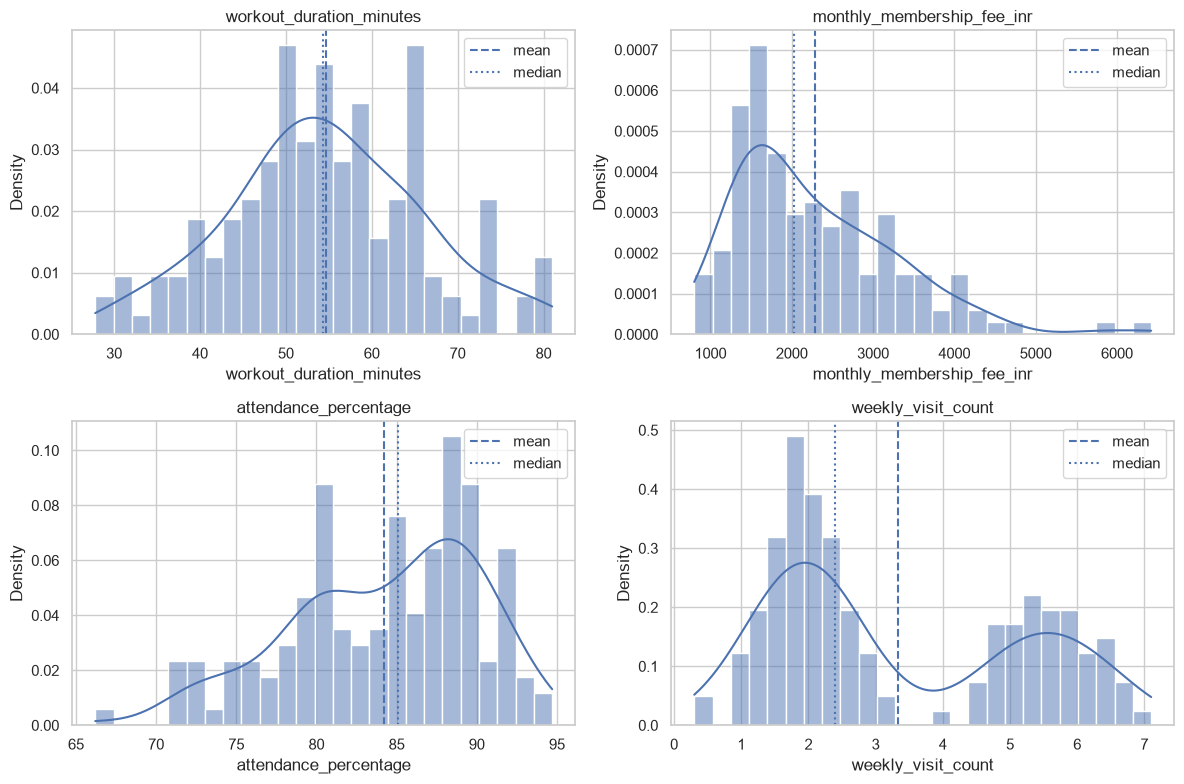

In [22]:
plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
sns.histplot(data=df,x=FEATURES[0],bins=25,kde=True,stat="density")
plt.axvline(df[FEATURES[0]].mean(),linestyle="--",label="mean")
plt.axvline(df[FEATURES[0]].median(),linestyle=":",label="median")
plt.title(FEATURES[0])
plt.legend()

plt.subplot(2,2,2)
sns.histplot(data=df,x=FEATURES[1],bins=25,kde=True,stat="density")
plt.axvline(df[FEATURES[1]].mean(),linestyle="--",label="mean")
plt.axvline(df[FEATURES[1]].median(),linestyle=":",label="median")
plt.title(FEATURES[1])
plt.legend()

plt.subplot(2,2,3)
sns.histplot(data=df,x=FEATURES[2],bins=25,kde=True,stat="density")
plt.axvline(df[FEATURES[2]].mean(),linestyle="--",label="mean")
plt.axvline(df[FEATURES[2]].median(),linestyle=":",label="median")
plt.title(FEATURES[2])
plt.legend()

plt.subplot(2,2,4)
sns.histplot(data=df,x=FEATURES[3],bins=25,kde=True,stat="density")
plt.axvline(df[FEATURES[3]].mean(),linestyle="--",label="mean")
plt.axvline(df[FEATURES[3]].median(),linestyle=":",label="median")
plt.title(FEATURES[3])
plt.legend()

plt.tight_layout()
plt.show()

### Q10 

Does the histogram for the feature you predicted in Q8 confirm or contradict your prediction?
If your prediction was wrong, which feature actually turned out to be bimodal, and does the mean
computed in Q2 fall in a sensible place on that histogram, or does it fall in an empty "valley"?

**Your answer:**
The histogram contradicts my prediction from Q8. The feature that actually turned out to be bimodal is weekly_study_hours, which has two distinct peaks. The mean from Q2 falls in the empty valley between the two peaks, so it does not represent a typical student very well.

### Q11  — Box plots

Standardize (z-score) the four numeric features — `z = (x - mean) / std` — and plot all four as **box plots side by side** on one figure, so their spreads are visually comparable despite being ondifferent original scales (₹, minutes, %, visits). Label the y-axis clearly. Briefly note in the plot title or a code comment which feature(s) show visible outlier points.

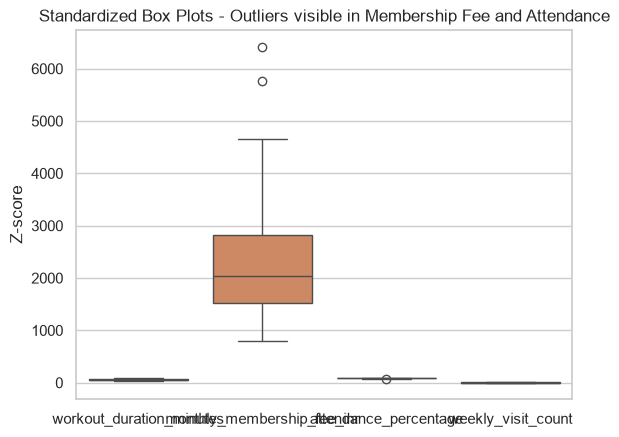

In [23]:

df["z_workout_duration"] = (df["workout_duration_minutes"] - df["workout_duration_minutes"].mean()) / df["workout_duration_minutes"].std()

df["z_membership_fee"] = (df["monthly_membership_fee_inr"] - df["monthly_membership_fee_inr"].mean()) / df["monthly_membership_fee_inr"].std()

df["z_attendance"] = (df["attendance_percentage"] - df["attendance_percentage"].mean()) / df["attendance_percentage"].std()

df["z_weekly_visits"] = (df["weekly_visit_count"] - df["weekly_visit_count"].mean()) / df["weekly_visit_count"].std()

sns.boxplot(data=df[FEATURES])
plt.title("Standardized Box Plots - Outliers visible in Membership Fee and Attendance")
plt.ylabel("Z-score")
plt.show()

### Q12 — Scatter plots

Choose **two pairs** of numeric features: one pair you hypothesize has a real relationship, and one
pair you hypothesize has little to no relationship. For each pair: compute the Pearson correlation
coefficient (`.corr()`), make a scatter plot, and put the correlation value in the plot title.

**Your answer (1–2 sentences per pair):** Did the scatter plots and correlation values support your
hypotheses? If a result surprised you, say so.
The scatter plot and correlation value (r ≈ -0.01) support my hypothesis that these features have little to no relationship.

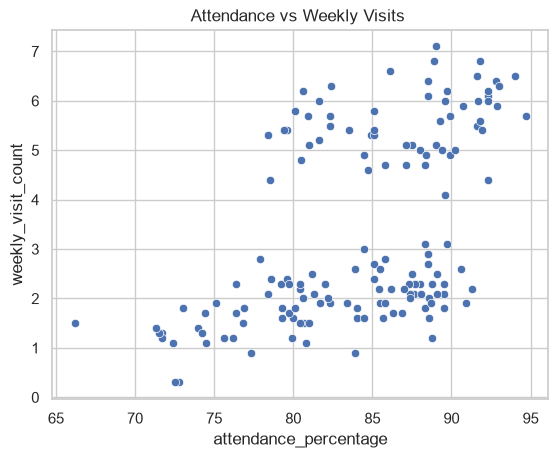

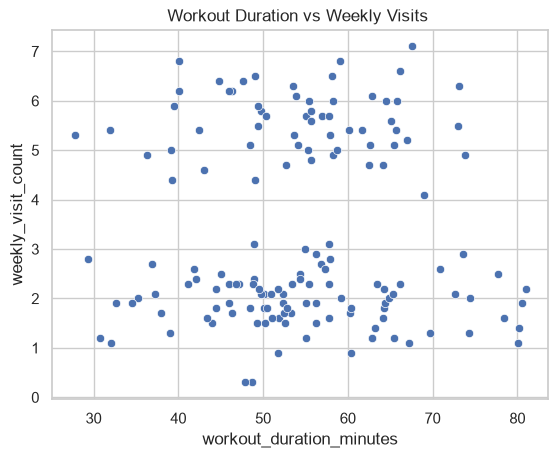

In [27]:
corr1 = df["attendance_percentage"].corr(df["weekly_visit_count"])

sns.scatterplot(data=df, x="attendance_percentage", y="weekly_visit_count")
plt.title("Attendance vs Weekly Visits ")
plt.show()
corr2 = df["workout_duration_minutes"].corr(df["weekly_visit_count"])

sns.scatterplot(data=df, x="workout_duration_minutes", y="weekly_visit_count")
plt.title("Workout Duration vs Weekly Visits ")
plt.show()

## Part 6 — Synthesis

### Q13 

Build **one summary table** with a row per numeric feature and columns for: mean, median, standard
deviation, IQR, skewness, and excess kurtosis (you have already computed all of these in Q2, Q5–Q7
— this question is about assembling them, not recomputing from scratch).

Then write a short paragraph (roughly 100–150 words) that, **for each of the four features**,
recommends which central-tendency measure (mean or median) and which dispersion measure (standard
deviation or IQR) should be reported, and briefly justifies the choice using the specific evidence
in your own table (not general rules quoted from Lab 3).

In [28]:
print("Mean:")
print(df[FEATURES].mean())

print("Median:")
print(df[FEATURES].median())

print("Standard Deviation:")
print(df[FEATURES].std())

print("IQR:")
print(df[FEATURES].quantile(0.75) - df[FEATURES].quantile(0.25))

print("Skewness:")
print(df[FEATURES].skew())

print("Excess Kurtosis:")
print(df[FEATURES].kurt())

Mean:
workout_duration_minutes        54.618
monthly_membership_fee_inr    2283.067
attendance_percentage           84.210
weekly_visit_count               3.337
dtype: float64
Median:
workout_duration_minutes        54.35
monthly_membership_fee_inr    2030.00
attendance_percentage           85.10
weekly_visit_count               2.40
dtype: float64
Standard Deviation:
workout_duration_minutes       11.397
monthly_membership_fee_inr    984.837
attendance_percentage           5.874
weekly_visit_count              1.886
dtype: float64
IQR:
workout_duration_minutes        14.825
monthly_membership_fee_inr    1310.000
attendance_percentage            8.600
weekly_visit_count               3.500
dtype: float64
Skewness:
workout_duration_minutes      0.081
monthly_membership_fee_inr    1.177
attendance_percentage        -0.561
weekly_visit_count            0.446
dtype: float64
Excess Kurtosis:
workout_duration_minutes     -0.160
monthly_membership_fee_inr    1.863
attendance_percentage      

**Your answer (recommendation paragraph):**

### Paragraph (100–150 words)

For **exam_score**, the mean and standard deviation should be reported because its skewness is close to zero, showing that the distribution is fairly symmetric. For **monthly_allowance_inr**, the median and IQR are more appropriate because the positive skewness indicates that the data is pulled toward higher values, making the median more representative. For **quiz_score**, the median and IQR should be reported because its negative skewness shows that the distribution is not symmetric. Finally, for **weekly_study_hours**, the median and IQR are preferable because the feature has a bimodal distribution, meaning the data contains two distinct groups. The table’s skewness and kurtosis values, together with the differences between mean and median, provide evidence for choosing the measures rather than relying only on general rules.



---

## Bonus (optional)

Group `df` by `preferred_workout` (`df.groupby("preferred_workout")`) and compare the mean
`attendance_percentage` across the four workout categories. Is attendance noticeably different for
any one category? Give one plausible real-world explanation for what you find (or for why there's
no real difference, if that's what you observe).

In [13]:
# TODO (bonus): groupby preferred_workout, compare mean attendance_percentage across categories

---

### Before you submit
- [ ] Ran the notebook top to bottom with no errors (Kernel → Restart & Run All)
- [ ] Every `# TODO` cell has working code, not just comments
- [ ] Every "Your answer" cell has a written response in your own words
- [ ] Did not modify the Part 1 dataset-generation code or the random seed